## Seaborn

In [1]:
import pandas as pd
import sqlite3
import matplotlib.pyplot as plt
import seaborn as sns

conn = sqlite3.connect('../data/checking-logs.sqlite')
query = """
    SELECT
        uid,
        timestamp
    FROM checker
    WHERE uid LIKE 'user_%'
        AND labname = 'project1'
        AND status = 'ready'
"""

df = pd.read_sql(query, conn, parse_dates=['timestamp'])
conn.close()


## data processing

In [2]:
df = df.sort_values('timestamp')
df['commit_count'] = 1
df['numTrials'] = df.groupby('uid')['commit_count'].cumsum()
df.tail()

,uid,timestamp,commit_count,numTrials
946,user_19,2020-05-15 10:22:39.698523,1,26
947,user_19,2020-05-15 10:22:46.248162,1,27
948,user_19,2020-05-15 10:23:18.043212,1,28
949,user_28,2020-05-15 10:38:14.430013,1,27
950,user_19,2020-05-15 10:52:23.922331,1,29


## visual

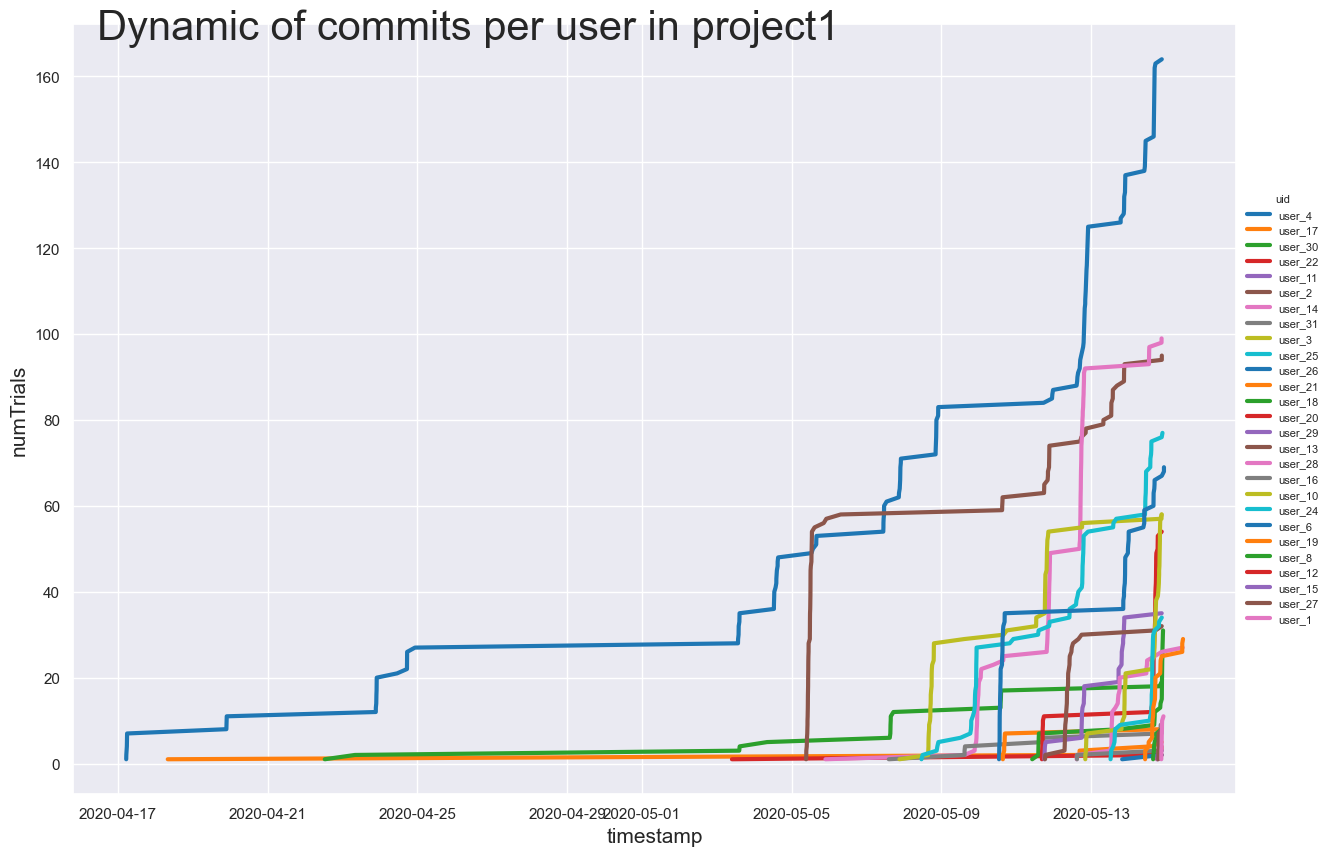

In [3]:
sns.set_theme(style='darkgrid')
plt.figure(figsize=(15, 10))
ax = sns.lineplot(
    data=df,
    x='timestamp',
    y='numTrials',
    hue='uid',
    linewidth=3,
    palette='tab10'
)
plt.text(0.02, 0.98,
    'Dynamic of commits per user in project1',
    fontsize=30,
    transform=plt.gca().transAxes
    )
plt.xlabel('timestamp', fontsize=15)
plt.ylabel('numTrials', fontsize=15)
plt.legend(title='uid', bbox_to_anchor=(1.08, 0.5), fontsize=8, title_fontsize=8, frameon=False, loc='center right')
plt.show()

### Which user was the leader in the number of commits almost all of the time?

Answer: user_4

### Which user was the leader for only a short period of time?

Answer: user_2